# Inspecting INSTANCE Data

Source page: https://www.pi.ingv.it/instance/ 

Licence CC BY 4.0. Cite Michelini et al. 2021, ESSD 13(12), 5509-5544, doi:10.5194/essd-13-5509-2021 and the dataset DOI 10.13127/instance.

In [ ]:
import os, subprocess
DOWNLOAD = True
DL_DIR = "/kaggle/temp/instance" if os.path.exists("/kaggle/input") else "instance_sample"
DL_URL = "http://repo.pi.ingv.it/instance/Instance_sample_dataset_v3.tar.bz2"
if DOWNLOAD:
    os.makedirs(DL_DIR, exist_ok=True)
    tarf = os.path.join(DL_DIR, "sample_v3.tar.bz2")
    if not os.path.exists(tarf):
        has_wget = subprocess.run("which wget", shell=True, capture_output=True).returncode == 0
        cmd = ["wget", "-q", "-O", tarf, DL_URL] if has_wget else ["curl", "-L", "-s", "-o", tarf, DL_URL]
        r = subprocess.run(cmd)
        print("download return code:", r.returncode)
    import tarfile
    with tarfile.open(tarf, "r:bz2") as t: t.extractall(DL_DIR)
    os.remove(tarf)
    print("unpacked into", DL_DIR)

download return code: 0


/tmp/ipykernel_16/174144298.py:14: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  with tarfile.open(tarf, "r:bz2") as t: t.extractall(DL_DIR)


unpacked into /kaggle/temp/instance


In [ ]:
import os, re, glob, json, sys, time, subprocess, traceback, inspect
import numpy as np, pandas as pd, h5py
import matplotlib.pyplot as plt

ON_KAGGLE = os.path.exists("/kaggle/input")
INSTANCE_DIR = DL_DIR if DOWNLOAD else None
EVENTS_CSV = None
NOISE_CSV  = None
STEAD_MIX_H5 = None
STEAD_CSV    = None
FS_ASSUMED = 100.0      # in Hz
OUT = "/kaggle/working/inspect_out" if ON_KAGGLE else os.path.join(os.getcwd(), "inspect_out")
os.makedirs(OUT, exist_ok=True)
S = {}                  # Summary JSON Initialization
def find_one(name):
    hits = glob.glob(f"/kaggle/input/**/{name}", recursive=True) if ON_KAGGLE else []
    return hits[0] if hits else None

root = INSTANCE_DIR or ("/kaggle/input" if ON_KAGGLE else None)
assert root and os.path.isdir(root), "Set INSTANCE_DIR to the folder with the INSTANCE sample."
STEAD_MIX_H5 = STEAD_MIX_H5 or find_one("training_datasets_STEAD_waveform_snr_40.hdf5")
STEAD_CSV    = STEAD_CSV or find_one("merged.csv")
print("search root     :", root)
print("STEAD mix file  :", STEAD_MIX_H5)
print("STEAD merged.csv:", STEAD_CSV)
print("output folder   :", OUT)
print("numpy", np.__version__, "| pandas", pd.__version__, "| h5py", h5py.__version__)

search root     : /kaggle/temp/instance
STEAD mix file  : /kaggle/input/datasets/prabhanshu22/wdn-training-data/training_datasets_STEAD_waveform_snr_40.hdf5
STEAD merged.csv: None
output folder   : /kaggle/working/inspect_out
numpy 2.1.3 | pandas 2.3.3 | h5py 3.14.0


In [ ]:
# File Inspection 

rows = []
for dp, dn, fn in os.walk(root):
    for f in fn:
        p = os.path.join(dp, f)
        try: rows.append((os.path.relpath(p, root), os.path.getsize(p)))
        except OSError: pass
files = pd.DataFrame(rows, columns=["path", "bytes"]).sort_values("path")
files = files[~files.path.apply(lambda p: os.path.basename(p).startswith("._"))].reset_index(drop=True)
files["MB"] = (files.bytes / 1e6).round(2)
files.to_csv(f"{OUT}/file_list.csv", index=False)
pd.set_option("display.width", 200, "display.max_colwidth", 120, "display.max_rows", 200)
files = files[~files.path.str.contains("wdn-runs-seed99|wdn-training-data")].reset_index(drop=True)
if not files.path.str.lower().str.endswith((".csv", ".csv.gz")).any() or not files.path.str.lower().str.endswith((".hdf5", ".h5", ".hdf")).any():
    raise RuntimeError("No INSTANCE files (CSV + HDF5) found under " + root + ". Set DOWNLOAD = True in the download cell (Internet must be ON), "
                       "or attach the INSTANCE sample as an input dataset, or set INSTANCE_DIR. Then restart and run all cells.")
print(f"{len(files)} files, total {files.bytes.sum()/1e9:.2f} GB")
print(files[["path", "MB"]].to_string(index=False))
S["n_files"] = int(len(files)); S["total_GB"] = round(files.bytes.sum()/1e9, 3)

5 files, total 3.05 GB
                                     path      MB
     data/Instance_events_counts_10k.hdf5 1444.06
         data/Instance_events_gm_10k.hdf5 1444.06
              data/Instance_noise_1k.hdf5  144.40
metadata/metadata_Instance_events_10k.csv   12.68
  metadata/metadata_Instance_noise_1k.csv    0.31


In [4]:
csv_paths  = [os.path.join(root, p) for p in files.path if p.lower().endswith((".csv", ".csv.gz"))]
h5_paths   = [os.path.join(root, p) for p in files.path if p.lower().endswith((".hdf5", ".h5", ".hdf"))]
other = [p for p in files.path if not p.lower().endswith((".csv", ".csv.gz", ".hdf5", ".h5", ".hdf"))]
print("CSV :", len(csv_paths), "| HDF5:", len(h5_paths), "| other:", len(other))
if other: print("other files:", other[:20])

META = {}
for p in csv_paths:
    try:
        df = pd.read_csv(p, low_memory=False)
        META[p] = df
        print("\n" + "=" * 100); print(os.path.relpath(p, root), df.shape)
        print("columns:", list(df.columns))
        print(df.head(3).T.to_string())
    except Exception as e:
        print("could not read", p, "->", repr(e))

H5INFO = {}
for p in h5_paths:
    print("\n" + "=" * 100); print(os.path.relpath(p, root))
    try:
        with h5py.File(p, "r") as f:
            print("top-level keys:", list(f.keys())[:10], "| attrs:", dict(f.attrs))
            grp = f["data"] if "data" in f else f
            names = list(grp.keys())
            first = grp[names[0]]
            H5INFO[p] = dict(group="data" if "data" in f else "/", n=len(names),
                             shape=tuple(first.shape), dtype=str(first.dtype))
            print(f"group '{H5INFO[p]['group']}': {len(names)} entries; first = {names[0]!r}")
            print("  shape", first.shape, "dtype", first.dtype, "| attrs:", dict(first.attrs))
            print("  shapes seen in first 200 entries:", sorted({tuple(grp[n].shape) for n in names[:200]}))
    except Exception as e:
        print("could not open ->", repr(e))
S["h5_files"] = {os.path.relpath(k, root): v for k, v in H5INFO.items()}

CSV : 2 | HDF5: 3 | other: 0

metadata/metadata_Instance_events_10k.csv (10000, 115)
columns: ['source_id', 'station_network_code', 'station_code', 'station_location_code', 'station_channels', 'station_latitude_deg', 'station_longitude_deg', 'station_elevation_m', 'station_vs_30_mps', 'station_vs_30_detail', 'source_origin_time', 'source_latitude_deg', 'source_longitude_deg', 'source_depth_km', 'source_origin_uncertainty_s', 'source_latitude_uncertainty_deg', 'source_longitude_uncertainty_deg', 'source_depth_uncertainty_km', 'source_stderror_s', 'source_gap_deg', 'source_horizontal_uncertainty_km', 'source_magnitude', 'source_magnitude_type', 'source_mt_eval_mode', 'source_mt_status', 'source_mt_scalar_moment_Nm', 'source_mechanism_strike_dip_rake', 'source_mechanism_moment_tensor', 'path_travel_time_P_s', 'path_travel_time_S_s', 'path_residual_P_s', 'path_residual_S_s', 'path_ep_distance_km', 'path_hyp_distance_km', 'path_azimuth_deg', 'path_backazimuth_deg', 'path_weight_phase_locati

### CSV Matching

In [ ]:
# trace_name -> hdf5 file

LOC = {}
GM_FILES = [p for p in H5INFO if "gm" in re.split(r"[_.\-]", os.path.basename(p).lower())]
print("ground-motion files (NOT used; same trace names as the counts files):", [os.path.basename(p) for p in GM_FILES])
S["ground_motion_files_ignored"] = [os.path.basename(p) for p in GM_FILES]
for p, info in H5INFO.items():
    if p in GM_FILES: continue
    with h5py.File(p, "r") as f:
        grp = f[info["group"]] if info["group"] != "/" else f
        for n in grp.keys(): LOC[n] = p
print("traces found in all HDF5 files:", len(LOC))

def role(df, path):
    cols = set(df.columns)
    if "trace_name" not in cols: return None
    return "events" if ("source_magnitude" in cols or "trace_P_arrival_sample" in cols) else "noise"

roles = {p: role(df, p) for p, df in META.items()}
print({os.path.relpath(p, root): r for p, r in roles.items()})
ev_candidates = [p for p, r in roles.items() if r == "events"]
no_candidates = [p for p, r in roles.items() if r == "noise"]
ev_path = EVENTS_CSV or (max(ev_candidates, key=lambda p: len(META[p])) if ev_candidates else None)
no_path = NOISE_CSV  or (max(no_candidates, key=lambda p: len(META[p])) if no_candidates else None)
print("GUESS events csv:", ev_path and os.path.relpath(ev_path, root))
print("GUESS noise csv :", no_path and os.path.relpath(no_path, root))
print("If either is wrong, set EVENTS_CSV / NOISE_CSV in cell 0 and rerun from here.")

def load(path):
    if path is None: return None
    d = META.get(path)
    if d is None: d = pd.read_csv(path, low_memory=False)
    d = d.copy(); d["in_h5"] = d["trace_name"].isin(LOC.keys()); return d

EV, NO = load(ev_path), load(no_path)
for tag, d in (("events", EV), ("noise", NO)):
    if d is None: print(f"{tag}: no metadata csv found"); continue
    print(f"{tag}: {len(d)} metadata rows, {int(d.in_h5.sum())} with a waveform in HDF5")
    S[f"{tag}_rows_meta"] = int(len(d)); S[f"{tag}_rows_with_waveform"] = int(d.in_h5.sum())

known = set()
for d in (EV, NO):
    if d is not None: known |= set(d.trace_name)
S["h5_traces_without_metadata"] = int(len(set(LOC) - known))
print("HDF5 traces with no metadata row:", S["h5_traces_without_metadata"])
EVp = EV[EV.in_h5].copy() if EV is not None else None
NOp = NO[NO.in_h5].copy() if NO is not None else None
if EVp is not None and "source_id" in EVp: 
    S["events_unique_source_id"] = int(EVp.source_id.nunique()); print("unique source_id (earthquakes):", S["events_unique_source_id"])
if NOp is None or len(NOp) == 0:
    print("\n>>> NO NOISE WAVEFORMS FOUND IN THE SAMPLE. Record this; the noise part then needs the separate noise download (3.9 GB counts).")

ground-motion files (NOT used; same trace names as the counts files): ['Instance_events_gm_10k.hdf5']
traces found in all HDF5 files: 11000
{'metadata/metadata_Instance_events_10k.csv': 'events', 'metadata/metadata_Instance_noise_1k.csv': 'noise'}
GUESS events csv: metadata/metadata_Instance_events_10k.csv
GUESS noise csv : metadata/metadata_Instance_noise_1k.csv
If either is wrong, set EVENTS_CSV / NOISE_CSV in cell 0 and rerun from here.
events: 10000 metadata rows, 10000 with a waveform in HDF5
noise: 1000 metadata rows, 1000 with a waveform in HDF5
HDF5 traces with no metadata row: 0
unique source_id (earthquakes): 300


### Array layout, units, time axis, component order

In [6]:
def get_trace(name):
    with h5py.File(LOC[name], "r") as f:
        g = f[H5INFO[LOC[name]]["group"]] if H5INFO[LOC[name]]["group"] != "/" else f
        return np.array(g[name])

def time_first(a):
    """Return (L, 3). Raises if neither axis has length 3."""
    if a.ndim != 2: raise ValueError(f"expected 2 dims, got {a.shape}")
    if a.shape[1] == 3: return a, "stored (L,3)"
    if a.shape[0] == 3: return a.T, "stored (3,L), transposed"
    raise ValueError(f"no axis of length 3 in {a.shape}")

ex_name = (EVp.trace_name.iloc[0] if EVp is not None and len(EVp) else next(iter(LOC)))
a = get_trace(ex_name)
arr, how = time_first(a)
S["trace_array_shape"] = list(a.shape); S["trace_dtype"] = str(a.dtype); S["trace_layout"] = how
S["trace_length_samples"] = int(arr.shape[0])
print("example trace:", ex_name)
print("array shape:", a.shape, "dtype:", a.dtype, "->", how)
print(f"length {arr.shape[0]} samples = {arr.shape[0]/FS_ASSUMED:.1f} s if the rate is {FS_ASSUMED:g} Hz")
print("per-axis min/max/std:", [(float(arr[:,i].min()), float(arr[:,i].max()), float(arr[:,i].std())) for i in range(3)])
print("NaN count:", int(np.isnan(arr).sum()))

# metadata columns that could say something about channels, units, sampling rate, timing
dfm = EVp if EVp is not None else NOp
if dfm is not None:
    keys = [c for c in dfm.columns if re.search(r"chan|compon|unit|samp|rate|freq|start|length|instr|sensor|gain|resp|trace_dt|npts", c, re.I)]
    print("\nmetadata columns about channels / units / sampling / timing:")
    for c in keys: print(f"  {c}: {dfm[c].dropna().astype(str).value_counts().head(6).to_dict()}")
    S["channel_unit_rate_columns"] = {c: dfm[c].dropna().astype(str).value_counts().head(6).to_dict() for c in keys}

example trace: 11030611.IV.OFFI..HH
array shape: (3, 12000) dtype: int32 -> stored (3,L), transposed
length 12000 samples = 120.0 s if the rate is 100 Hz
per-axis min/max/std: [(-4913.0, 6442.0, 634.5511605530005), (-8726.0, 7355.0, 702.3805788243719), (-3051.0, 3229.0, 417.6918443886909)]
NaN count: 0

metadata columns about channels / units / sampling / timing:
  station_channels: {'HH': 3893, 'HN': 3550, 'EH': 2517, 'HL': 40}
  source_mechanism_strike_dip_rake: {}
  source_mechanism_moment_tensor: {}
  trace_start_time: {'2016-12-07T07:00:00.00Z': 4, '2016-12-07T08:00:00.00Z': 4, '2016-12-07T06:47:21.34Z': 3, '2016-12-07T06:47:16.87Z': 3, '2016-12-04T20:22:14.60Z': 2, '2016-12-09T03:39:25.25Z': 2}
  trace_dt_s: {'0.01': 10000}
  trace_npts: {'12000': 10000}
  trace_P_arrival_sample: {'1780': 47, '1898': 45, '1978': 45, '1932': 42, '1773': 41, '1889': 41}
  trace_S_arrival_sample: {'2039.0': 17, '2007.0': 15, '1962.0': 15, '2250.0': 15, '2030.0': 15, '1982.0': 14}
  trace_deconvolved

In [ ]:
if EVp is not None and {"trace_P_arrival_sample", "trace_S_arrival_sample"} <= set(EVp.columns):
    sub = EVp.dropna(subset=["trace_P_arrival_sample", "trace_S_arrival_sample"])
    sub = sub[(sub.trace_S_arrival_sample - sub.trace_P_arrival_sample) > 2 * FS_ASSUMED].sample(min(300, len(sub)), random_state=0)
    ratios = []
    w = int(2 * FS_ASSUMED)
    for _, r in sub.iterrows():
        try:
            x, _ = time_first(get_trace(r.trace_name)); p, s = int(r.trace_P_arrival_sample), int(r.trace_S_arrival_sample)
            if p + w > len(x) or s + w > len(x): continue
            rp = np.sqrt((x[p:p+w] ** 2).mean(0)); rs = np.sqrt((x[s:s+w] ** 2).mean(0))
            ratios.append(rp / (rs + 1e-30))
        except Exception: pass
    ratios = np.array(ratios)
    if len(ratios):
        med = np.median(ratios, axis=0)
        print(f"{len(ratios)} traces used. median P/S RMS ratio per array axis: {np.round(med, 3).tolist()}")
        print("GUESS: the axis with the highest ratio is the vertical (Z). Compare with the channel metadata above; do not trust either alone.")
        S["PS_ratio_median_per_axis"] = np.round(med, 4).tolist()
else:
    print("no P/S arrival columns; skipped")

/tmp/ipykernel_16/1574286414.py:12: RuntimeWarning: invalid value encountered in sqrt
  rp = np.sqrt((x[p:p+w] ** 2).mean(0)); rs = np.sqrt((x[s:s+w] ** 2).mean(0))


300 traces used. median P/S RMS ratio per array axis: [0.252, nan, 0.482]
GUESS: the axis with the highest ratio is the vertical (Z). Compare with the channel metadata above; do not trust either alone.


### Magnitude, SNR, arrivals

In [ ]:

for c in ("trace_dt_s", "trace_npts"):
    if EVp is not None and c in EVp: print(c, EVp[c].value_counts().head(5).to_dict()); S["meta_" + c] = EVp[c].value_counts().head(5).to_dict()
    if NOp is not None and c in NOp: print("noise", c, NOp[c].value_counts().head(5).to_dict()); S["meta_noise_" + c] = NOp[c].value_counts().head(5).to_dict()

trace_dt_s {0.01: 10000}
noise trace_dt_s {0.01: 1000}
trace_npts {12000: 10000}
noise trace_npts {12000: 1000}


magnitude quantiles: {'0%': 0.5, '1%': 0.9, '5%': 1.2, '25%': 2.0, '50%': 2.2, '75%': 2.7, '90%': 3.3, '95%': 3.5, '99%': 4.5, '100%': 4.8}
SNR columns used: ['trace_E_snr_db', 'trace_N_snr_db', 'trace_Z_snr_db']
mean-SNR quantiles (dB): {'0%': -14.991, '1%': -1.374, '5%': 1.867, '25%': 11.115, '50%': 20.819, '75%': 32.395, '90%': 43.312, '95%': 49.734, '99%': 62.864, '100%': 88.529}
NaN in mean SNR: 10

NOTE: the INSTANCE SNR (95th percentile of |amp| after S over before P) is not the STEAD definition.

pool size after the mean-SNR filter (STEAD recipe uses >= 40 dB):
 threshold_dB  traces  unique_earthquakes  unique_stations
           40    1355                 136              142
           35    2041                 169              174
           30    2961                 207              226
           25    3988                 234              261
           20    5204                 257              285
           15    6519                 283              314
           

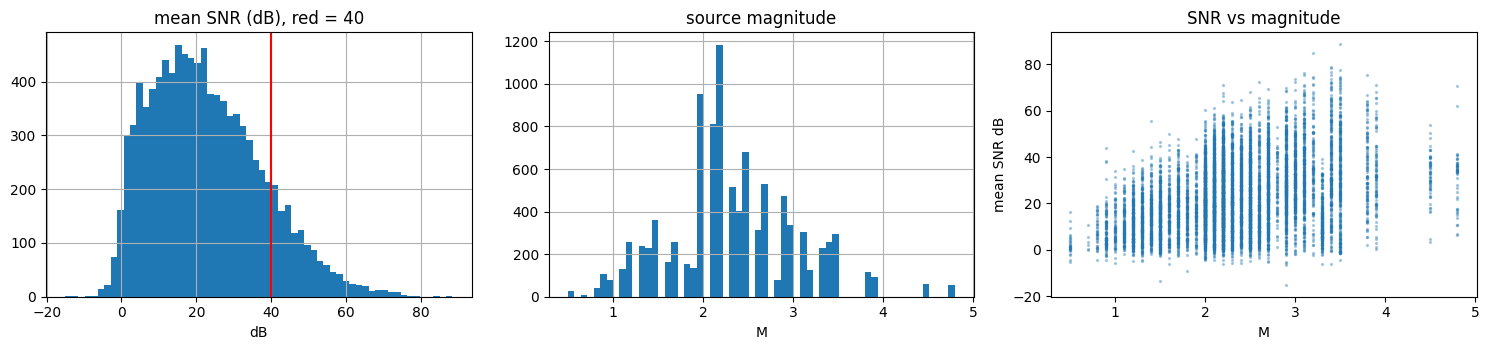


value counts of 'station_channels': {'HH': 3893, 'HN': 3550, 'EH': 2517, 'HL': 40}
pool at >= 40 dB / >= 30 dB by this column:
                  >=40  >=30   all
station_channels                  
EH                 652  1157  2517
HH                 319   838  3893
HL                   2     3    40
HN                 382   963  3550


In [ ]:
def q(x, qs=(0, .01, .05, .25, .5, .75, .9, .95, .99, 1)):
    x = pd.Series(x).dropna(); return {f"{int(k*100)}%": round(float(x.quantile(k)), 3) for k in qs}

if EVp is not None and len(EVp):
    if "source_magnitude" in EVp:
        print("magnitude quantiles:", q(EVp.source_magnitude)); S["magnitude_quantiles"] = q(EVp.source_magnitude)
    snr_cols = [c for c in EVp.columns if re.fullmatch(r"trace_[ENZ12]_snr_db", c)] or [c for c in EVp.columns if "snr" in c.lower()]
    print("SNR columns used:", snr_cols)
    S["snr_columns"] = snr_cols
    EVp["snr_mean_db"] = EVp[snr_cols].mean(axis=1)
    EVp["snr_min_db"]  = EVp[snr_cols].min(axis=1)
    print("mean-SNR quantiles (dB):", q(EVp.snr_mean_db)); S["snr_mean_quantiles"] = q(EVp.snr_mean_db)
    print("NaN in mean SNR:", int(EVp.snr_mean_db.isna().sum()))
    print("\nNOTE: the INSTANCE SNR (95th percentile of |amp| after S over before P) is not the STEAD definition.")

    # pool size per threshold, with the channel family if a channel column exists
    chan_col = next((c for c in EVp.columns if re.search(r"channel", c, re.I)), None)
    thr = [40, 35, 30, 25, 20, 15, 10, 0]
    tab = []
    for t_ in thr:
        m = EVp.snr_mean_db >= t_
        row = {"threshold_dB": t_, "traces": int(m.sum()), "unique_earthquakes": int(EVp[m].source_id.nunique()) if "source_id" in EVp else None,
               "unique_stations": int(EVp[m].station_code.nunique()) if "station_code" in EVp else None}
        tab.append(row)
    tab = pd.DataFrame(tab); print("\npool size after the mean-SNR filter (STEAD recipe uses >= 40 dB):"); print(tab.to_string(index=False))
    tab.to_csv(f"{OUT}/snr_threshold_pool.csv", index=False); S["snr_threshold_pool"] = tab.to_dict("records")
    print("Reference: step2b draws 100,000 mixtures WITH replacement; a pool well below that means many repeats.")

    fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
    EVp.snr_mean_db.dropna().hist(bins=60, ax=ax[0]); ax[0].axvline(40, c="r"); ax[0].set_title("mean SNR (dB), red = 40"); ax[0].set_xlabel("dB")
    if "source_magnitude" in EVp: EVp.source_magnitude.dropna().hist(bins=60, ax=ax[1]); ax[1].set_title("source magnitude"); ax[1].set_xlabel("M")
    if "source_magnitude" in EVp: ax[2].scatter(EVp.source_magnitude, EVp.snr_mean_db, s=2, alpha=.3); ax[2].set_xlabel("M"); ax[2].set_ylabel("mean SNR dB"); ax[2].set_title("SNR vs magnitude")
    plt.tight_layout(); plt.savefig(f"{OUT}/instance_snr_magnitude.png", dpi=120); plt.show()

    if chan_col:
        print(f"\nvalue counts of '{chan_col}':", EVp[chan_col].value_counts().head(10).to_dict())
        print("pool at >= 40 dB / >= 30 dB by this column:")
        print(pd.DataFrame({">=40": EVp[EVp.snr_mean_db >= 40][chan_col].value_counts(), ">=30": EVp[EVp.snr_mean_db >= 30][chan_col].value_counts(),
                            "all": EVp[chan_col].value_counts()}).fillna(0).astype(int).head(10).to_string())
else:
    print("no event metadata with waveforms; skipped")

In [ ]:
if EVp is not None and "trace_P_arrival_sample" in EVp:
    L = S["trace_length_samples"]
    print("P arrival sample quantiles :", q(EVp.trace_P_arrival_sample))
    print("P arrival missing:", int(EVp.trace_P_arrival_sample.isna().sum()), "of", len(EVp))
    if "trace_S_arrival_sample" in EVp:
        print("S arrival sample quantiles :", q(EVp.trace_S_arrival_sample))
        print("S arrival missing:", int(EVp.trace_S_arrival_sample.isna().sum()))
        d = (EVp.trace_S_arrival_sample - EVp.trace_P_arrival_sample) / FS_ASSUMED
        print("S-P time (s) quantiles     :", q(d)); S["SminusP_s_quantiles"] = q(d)
    S["P_sample_quantiles"] = q(EVp.trace_P_arrival_sample)
    W = int(60 * FS_ASSUMED)
    rows = []
    for pre in (5, 10, 15, 20, 30):
        start = EVp.trace_P_arrival_sample - pre * FS_ASSUMED
        fits = (start >= 0) & (start + W <= L)
        has_pick = EVp.trace_S_arrival_sample.notna() if "trace_S_arrival_sample" in EVp else pd.Series(True, index=EVp.index)
        s_in = fits & has_pick & (EVp.trace_S_arrival_sample < start + W) if "trace_S_arrival_sample" in EVp else fits
        rows.append({"seconds_before_P": pre, "window_fits": round(float(fits.mean()), 4),
                     "fits_and_S_inside": round(float(s_in.mean()), 4),
                     "S_inside_among_traces_with_S_pick": round(float(s_in[has_pick].sum() / max(int(has_pick.sum()), 1)), 4)})
    crop = pd.DataFrame(rows); print("\nfraction of ALL traces where [P - pre, P - pre + 60 s] lies inside the trace (fits_and_S_inside counts a missing S pick as not inside):"); print(crop.to_string(index=False))
    crop.to_csv(f"{OUT}/crop_feasibility.csv", index=False); S["crop_feasibility"] = crop.to_dict("records")
    print("STEAD reference: not measured here. The crop offset is a team decision (see end).")

P arrival sample quantiles : {'0%': 1457.0, '1%': 1537.0, '5%': 1585.95, '25%': 1730.0, '50%': 1885.5, '75%': 2035.0, '90%': 2566.2, '95%': 3460.0, '99%': 4876.07, '100%': 6701.0}
P arrival missing: 0 of 10000
S arrival sample quantiles : {'0%': 1582.0, '1%': 1753.0, '5%': 1880.0, '25%': 2125.0, '50%': 2336.0, '75%': 2672.0, '90%': 3455.2, '95%': 4207.8, '99%': 5630.52, '100%': 7281.0}
S arrival missing: 3937
S-P time (s) quantiles     : {'0%': 0.46, '1%': 1.05, '5%': 1.561, '25%': 2.7, '50%': 3.9, '75%': 5.59, '90%': 7.878, '95%': 9.129, '99%': 14.242, '100%': 42.08}

fraction of ALL traces where [P - pre, P - pre + 60 s] lies inside the trace (fits_and_S_inside counts a missing S pick as not inside):
 seconds_before_P  window_fits  fits_and_S_inside  S_inside_among_traces_with_S_pick
                5       0.9998             0.6061                             0.9997
               10       1.0000             0.6063                             1.0000
               15       0.9998   

### Plots 

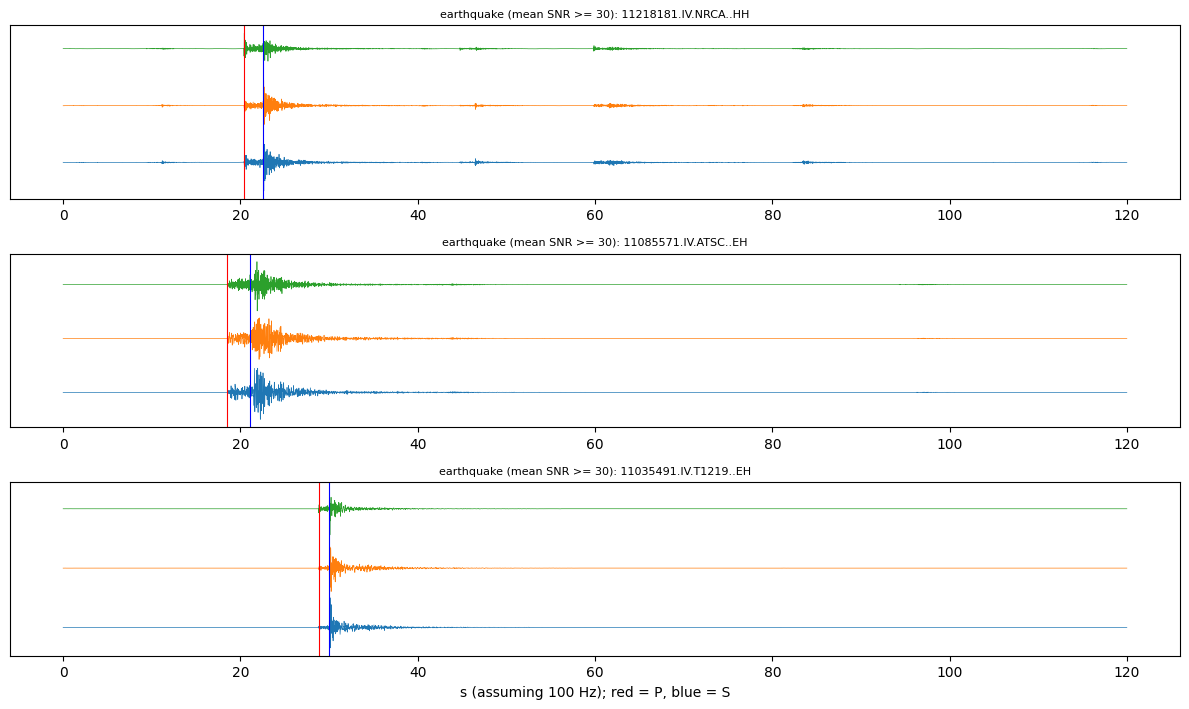

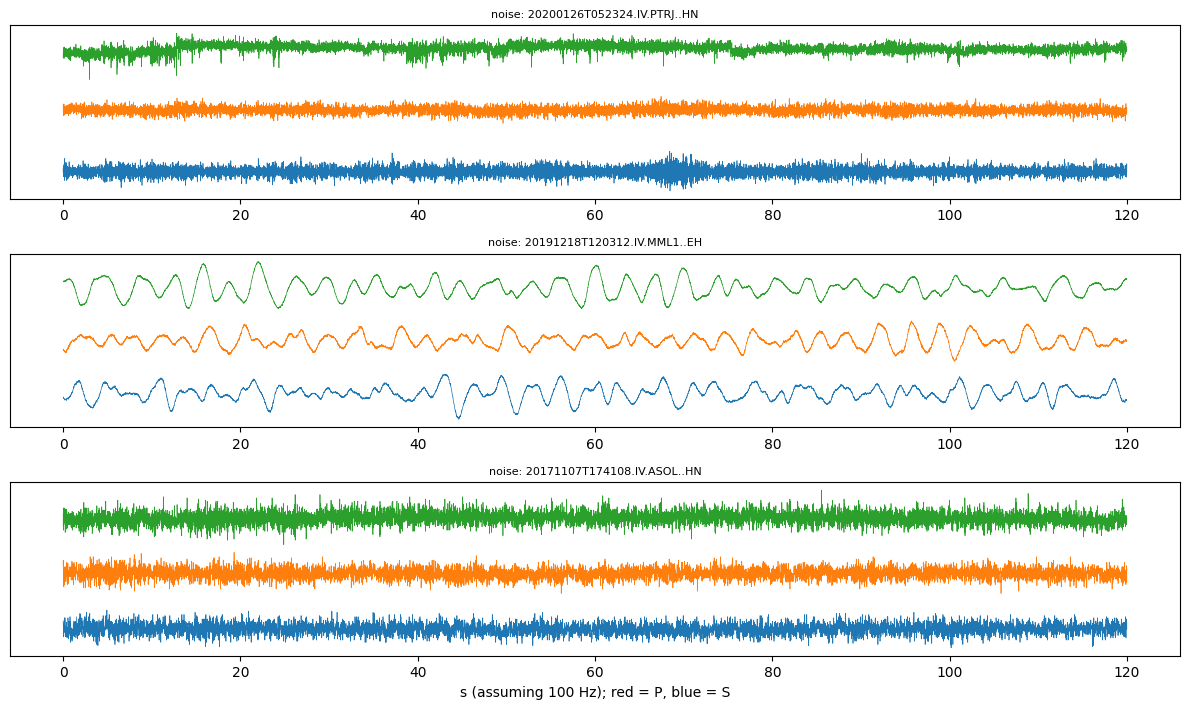

In [11]:
def plot_examples(df, title, n=3, fname=None, seed=0):
    if df is None or len(df) == 0: print("nothing to plot for", title); return
    pick = df.sample(min(n, len(df)), random_state=seed)
    fig, axs = plt.subplots(len(pick), 1, figsize=(12, 2.4 * len(pick)), squeeze=False)
    for ax, (_, r) in zip(axs[:, 0], pick.iterrows()):
        x, _ = time_first(get_trace(r.trace_name)); t = np.arange(len(x)) / FS_ASSUMED
        for i, c in enumerate("012"): ax.plot(t, x[:, i] / (np.abs(x).max() + 1e-30) + 2 * i, lw=.5, label=f"axis {i}")
        for col, colr in (("trace_P_arrival_sample", "r"), ("trace_S_arrival_sample", "b")):
            if col in r and pd.notna(r[col]): ax.axvline(r[col] / FS_ASSUMED, c=colr, lw=.8)
        ax.set_title(f"{title}: {r.trace_name}", fontsize=8); ax.set_yticks([])
    axs[-1, 0].set_xlabel("s (assuming 100 Hz); red = P, blue = S")
    plt.tight_layout()
    if fname: plt.savefig(f"{OUT}/{fname}", dpi=110)
    plt.show()
plot_examples(EVp[EVp.snr_mean_db >= 30] if EVp is not None and "snr_mean_db" in EVp else EVp, "earthquake (mean SNR >= 30)", fname="examples_earthquake.png")
plot_examples(NOp, "noise", fname="examples_noise.png")

### Overlap with STEAD (stations and networks)

In [12]:
def stead_names(path):
    out = []
    with h5py.File(path, "r") as f:
        for k in ("earthquake_name", "noise_name"):
            if k in f: out += [x.decode() if isinstance(x, bytes) else str(x) for x in np.array(f[k])]
    return out

if STEAD_MIX_H5 and EVp is not None:
    nm = stead_names(STEAD_MIX_H5)
    print("STEAD names read:", len(nm), "| unique:", len(set(nm))); print("examples:", nm[:5])
    parsed = {n.split("_")[0] for n in nm}                      # 'STA.NET'
    st_sta = {p.split(".")[0] for p in parsed}; st_net = {p.split(".")[-1] for p in parsed}
    print("STEAD stations in the mixtures:", len(st_sta), "| networks:", len(st_net))
    if {"station_code", "station_network_code"} <= set(EVp.columns):
        ins_pairs = {f"{s}.{n}" for s, n in zip(EVp.station_code, EVp.station_network_code)}
        ins_net = set(EVp.station_network_code.astype(str))
        both = ins_pairs & parsed; net_both = ins_net & st_net
        print("INSTANCE station.network pairs:", len(ins_pairs), "| networks:", sorted(ins_net)[:25])
        print("shared station.network pairs with STEAD mixtures:", len(both), sorted(both)[:20])
        print("shared network codes:", sorted(net_both))
        S["stead_overlap"] = dict(instance_pairs=len(ins_pairs), shared_pairs=len(both), shared_networks=sorted(net_both),
                                  stead_names_read=len(nm), note="only stations present in the 187k mixture file, not all of STEAD")
        print("\nCaveat: this is only the part of STEAD that was used in the mixtures (100k STEAD rows), not the whole STEAD.")
        print("A shared station is not a shared event. Event overlap needs origin times (next cell).")
    else:
        print("station_code / station_network_code not in the events metadata; columns are:", list(EVp.columns)[:60])
else:
    print("STEAD mixture file not found: attach the Kaggle dataset prabhanshu22/wdn-training-data or set STEAD_MIX_H5.")

STEAD names read: 200000 | unique: 155252
examples: ['CNCH.SV_20140323023014_EV', 'V33A.TA_20100916214144_EV', 'NEA2.AK_20140620010639_EV', 'DOM.SN_20151221232009_EV', 'B084.PB_20150529214239_EV']
STEAD stations in the mixtures: 2620 | networks: 146
INSTANCE station.network pairs: 363 | networks: ['BA', 'GU', 'HL', 'IV', 'IX', 'MN', 'NI', 'OT', 'OX', 'RF', 'SI', 'ST', 'TV', 'XO']
shared station.network pairs with STEAD mixtures: 81 ['ACER.IV', 'ACOM.NI', 'AGOR.NI', 'AGST.IV', 'AMUR.IV', 'AOI.IV', 'APPI.IV', 'AQU.MN', 'ARVD.IV', 'ASSB.IV', 'BADI.IV', 'BDI.IV', 'BNI.MN', 'BRMO.IV', 'CAFE.IV', 'CDCA.IV', 'CDRU.IV', 'CEL.MN', 'CERT.IV', 'CESI.IV']
shared network codes: ['BA', 'GU', 'HL', 'IV', 'MN', 'NI', 'RF']

Caveat: this is only the part of STEAD that was used in the mixtures (100k STEAD rows), not the whole STEAD.
A shared station is not a shared event. Event overlap needs origin times (next cell).


In [13]:
# Event overlap needs STEAD origin times: only possible with merged.csv
if STEAD_CSV and EVp is not None:
    st = pd.read_csv(STEAD_CSV, low_memory=False, usecols=lambda c: c in {"trace_category", "source_origin_time", "source_latitude", "source_longitude", "source_magnitude"})
    st = st[st.trace_category == "earthquake_local"].copy()
    st["t"] = pd.to_datetime(st.source_origin_time, errors="coerce", utc=True)
    tcol = next((c for c in EVp.columns if "origin_time" in c.lower()), None)
    print("INSTANCE time column:", tcol, "| STEAD earthquakes:", len(st))
    if tcol:
        ins = EVp.drop_duplicates("source_id") if "source_id" in EVp else EVp
        ins = ins.assign(t=pd.to_datetime(ins[tcol], errors="coerce", utc=True)).dropna(subset=["t"]).sort_values("t")
        st = st.dropna(subset=["t"]).sort_values("t")
        m = pd.merge_asof(ins[["t"]].reset_index(), st[["t"]].rename(columns={"t": "t_st"}).assign(t=lambda d: d.t_st), on="t", direction="nearest", tolerance=pd.Timedelta("5s"))
        print("INSTANCE events with a STEAD event within 5 s:", int(m.t_st.notna().sum()), "of", len(ins))
        S["event_overlap_5s"] = dict(matched=int(m.t_st.notna().sum()), instance_events=int(len(ins)))
        print("A time match is a candidate, not proof: check position and magnitude of a few before calling it a shared event.")
else:
    print("merged.csv not available: event-level overlap NOT checked. Say so in the report; do not claim 'no overlap'.")
    S["event_overlap_5s"] = "not checked (no merged.csv)"

merged.csv not available: event-level overlap NOT checked. Say so in the report; do not claim 'no overlap'.


In [ ]:
# Event-overlap PROXY without merged.csv: STEAD trace names carry the trace start time (STATION.NET_YYYYMMDDhhmmss_EV).
# An INSTANCE event is a CANDIDATE shared event if, at the same station.network, a STEAD trace starts within +-TOL_S of its origin time.
# Only STEAD earthquakes that were used in the mixtures are visible here, so this is a LOWER bound on the true overlap.

TOL_S = 120
if STEAD_MIX_H5 and EVp is not None and {"station_code", "station_network_code", "source_origin_time", "source_id"} <= set(EVp.columns):
    recs = []
    for n in nm:
        parts = n.split("_")
        if len(parts) >= 3 and parts[-1] == "EV":
            recs.append((parts[0], parts[1]))
    st_df = pd.DataFrame(recs, columns=["pair", "ts"]).drop_duplicates()
    st_df["t"] = pd.to_datetime(st_df.ts, format="%Y%m%d%H%M%S", errors="coerce", utc=True)
    st_df = st_df.dropna(subset=["t"])
    print("STEAD earthquake names with a parsable start time:", len(st_df), "| unparsable:", len(recs) - len(st_df))
    ins = EVp.drop_duplicates(["source_id", "station_code", "station_network_code"]).copy()
    ins["pair"] = ins.station_code.astype(str) + "." + ins.station_network_code.astype(str)
    ins["t"] = pd.to_datetime(ins.source_origin_time, errors="coerce", utc=True)
    ins = ins.dropna(subset=["t"])
    by_pair = {k: np.sort(v.t.values) for k, v in st_df.groupby("pair")}
    hit = []
    for pair, t0 in zip(ins.pair, ins.t.values):
        arr = by_pair.get(pair)
        if arr is None: hit.append(False); continue
        i = np.searchsorted(arr, t0)
        d = [abs((arr[j] - t0) / np.timedelta64(1, "s")) for j in (i - 1, i) if 0 <= j < len(arr)]
        hit.append(bool(d) and min(d) <= TOL_S)
    ins["candidate_shared"] = hit
    ev_hit = ins.groupby("source_id").candidate_shared.any()
    print(f"INSTANCE source_ids with a candidate STEAD match (same station, start within {TOL_S} s of origin): {int(ev_hit.sum())} of {len(ev_hit)}")
    print(f"INSTANCE (event, station) pairs with a candidate match: {int(ins.candidate_shared.sum())} of {len(ins)}")
    S["event_overlap_proxy"] = dict(tol_s=TOL_S, events_with_candidate=int(ev_hit.sum()), events=int(len(ev_hit)),
                                    pairs_with_candidate=int(ins.candidate_shared.sum()), pairs=int(len(ins)),
                                    note="lower bound; candidates, not proof; only STEAD traces used in the mixtures are visible")
    ins[ins.candidate_shared][["source_id", "pair", "source_origin_time", "source_magnitude"]].head(30).to_csv(f"{OUT}/event_overlap_candidates_head.csv", index=False)
    ev_hit[ev_hit].index.to_series().to_csv(f"{OUT}/source_ids_with_stead_candidate.csv", index=False)
else:
    print("proxy skipped (needs the STEAD mixture file and station / origin-time columns)")

STEAD earthquake names with a parsable start time: 73544 | unparsable: 26456
INSTANCE source_ids with a candidate STEAD match (same station, start within 120 s of origin): 1 of 300
INSTANCE (event, station) pairs with a candidate match: 1 of 6837


In [15]:
COMMIT = "afe2536cf29ead8b4d8d5c50ddf85cc1dd90ddd1"
repo = os.path.join(OUT, "WaveDecompNet-paper")
if not os.path.isdir(repo):
    r = subprocess.run(f"git clone -q https://github.com/yinjiuxun/WaveDecompNet-paper {repo} && git -C {repo} checkout -q {COMMIT}", shell=True, capture_output=True, text=True)
    print("clone:", r.returncode, r.stderr[-300:])
hits = glob.glob(f"{repo}/**/utilities.py", recursive=True)
print("utilities.py found:", hits)
if hits:
    src = open(hits[0]).read()
    m = re.search(r"def downsample_series.*?(?=\ndef |\Z)", src, re.S)
    print(m.group(0) if m else "downsample_series not found in the file")
    S["downsample_series_source"] = m.group(0)[:3000] if m else None
    try:
        sys.path.insert(0, os.path.dirname(hits[0]))
        from utilities import downsample_series
        fs = 100.0; t = np.arange(0, 6000) / fs
        x = np.stack([np.sin(2*np.pi*1.0*t) + np.sin(2*np.pi*8.0*t)] * 3, axis=1)
        _, y, _ = downsample_series(t, x, 10)
        y = np.asarray(y); fy = np.fft.rfftfreq(y.shape[0], d=0.1); sp = np.abs(np.fft.rfft(y[:, 0])) / y.shape[0] * 2
        amp = lambda f0: float(sp[np.argmin(np.abs(fy - f0))])
        print(f"\nafter downsampling: output shape {y.shape}")
        print(f"amplitude at 1 Hz (should stay ~1): {amp(1.0):.3f}")
        print(f"amplitude at 2 Hz (alias of 8 Hz; should be ~0 if anti-aliased): {amp(2.0):.3f}")
        S["downsample_alias_test"] = dict(amp_1Hz=amp(1.0), amp_alias_2Hz=amp(2.0), out_shape=list(y.shape))
    except Exception as e:
        print("could not import/run downsample_series:", repr(e)); traceback.print_exc()

clone: 0 
utilities.py found: ['/kaggle/working/inspect_out/WaveDecompNet-paper/utilities.py']
def downsample_series(time, series, f_downsampe):
    """Down sample the time series given a lower sampling frequency f_downsample,
    time_new, series_downsample, dt_new = downsample_series(time, series, f_downsampe)

    The time series has been lowpass filtered (f_filter=f_downsample/2) first,
    and then downsampled through interpolation.
    """
    dt = time[1] - time[0]
    # lowpass filter
    b, a = sgn.butter(4, f_downsampe / 2 * 2 * dt)
    series_filt = sgn.filtfilt(b, a, series, axis=0)
    # downsample through interpolation
    dt_new = 1 / f_downsampe
    # time_new = np.arange(time[0], time[-1] + dt_new, dt_new)
    time_new = np.arange(time[0], time[-1], dt_new)
    # series_downsample = np.interp(time_new, time, series_filt)
    interp_f = interp1d(time, series_filt, axis=0, bounds_error=False, fill_value=0.)
    series_downsample = interp_f(time_new)

    # plt.figure()
 

### Summary file

In [16]:
def default(o):
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, (np.floating,)): return float(o)
    return str(o)
with open(f"{OUT}/phase2_inspection_summary.json", "w") as f: json.dump(S, f, indent=1, default=default)
print(json.dumps({k: v for k, v in S.items() if k != "downsample_series_source"}, indent=1, default=default)[:6000])
print("\nSaved in", OUT, ":", sorted(os.listdir(OUT)))

{
 "n_files": 5,
 "total_GB": 3.046,
 "h5_files": {
  "data/Instance_events_counts_10k.hdf5": {
   "group": "data",
   "n": 10000,
   "shape": [
    3,
    12000
   ],
   "dtype": "int32"
  },
  "data/Instance_events_gm_10k.hdf5": {
   "group": "data",
   "n": 10000,
   "shape": [
    3,
    12000
   ],
   "dtype": "float32"
  },
  "data/Instance_noise_1k.hdf5": {
   "group": "data",
   "n": 1000,
   "shape": [
    3,
    12000
   ],
   "dtype": "int32"
  }
 },
 "ground_motion_files_ignored": [
  "Instance_events_gm_10k.hdf5"
 ],
 "events_rows_meta": 10000,
 "events_rows_with_waveform": 10000,
 "noise_rows_meta": 1000,
 "noise_rows_with_waveform": 1000,
 "h5_traces_without_metadata": 0,
 "events_unique_source_id": 300,
 "trace_array_shape": [
  3,
  12000
 ],
 "trace_dtype": "int32",
 "trace_layout": "stored (3,L), transposed",
 "trace_length_samples": 12000,
 "channel_unit_rate_columns": {
  "station_channels": {
   "HH": 3893,
   "HN": 3550,
   "EH": 2517,
   "HL": 40
  },
  "source_